Phase 0 : Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Phase 1 : Understand The Data

In [2]:
sales = pd.read_csv("sales.csv")

In [3]:
sales.head(10)

,Order_ID,Order_Date,Customer_ID,Category,Product,Quantity,Unit_Price,Discount,City,Payment_Method,Rating,Order_Status,Revenue_Before_Discount,Discount_Amount,Final_Revenue
0,ORD-005874,2025-10-23,CUST-12091,Sports,Running Shoes,3,4320,0.10,Luxor,Vodafone Cash,4.4,Delivered,12960,1296.0,11664.0
1,ORD-001411,2025-04-10,CUST-12192,Electronics,Power Bank,3,1240,0.00,Sohag,Instapay,4.0,Delivered,3720,0.0,3720.0
2,ORD-002686,2025-12-09,CUST-11769,Electronics,Power Bank,5,1670,0.00,Cairo,Vodafone Cash,3.0,Delivered,8350,0.0,8350.0
3,ORD-005556,2025-10-29,CUST-10022,Beauty,Moisturizer,4,840,0.05,Giza,Credit Card,4.2,Delivered,3360,168.0,3192.0
4,ORD-003827,2025-01-16,CUST-11113,Clothing,Jeans,5,740,0.05,Mansoura,Cash on Delivery,4.8,Delivered,3700,185.0,3515.0
5,ORD-005474,2025-01-26,CUST-11195,Beauty,Hair Dryer,4,1900,0.05,Mansoura,Vodafone Cash,3.4,Delivered,7600,380.0,7220.0
6,ORD-004072,2025-08-19,CUST-11325,Beauty,Hair Dryer,5,2840,0.05,Alexandria,Debit Card,3.8,Delivered,14200,710.0,13490.0
7,ORD-002200,2025-07-30,CUST-10839,Home & Kitchen,Air Fryer,4,3100,0.15,Cairo,Cash on Delivery,4.5,Delivered,12400,1860.0,10540.0
8,ORD-005455,2025-04-23,CUST-12183,Beauty,Hair Dryer,2,1490,0.00,Luxor,Cash on Delivery,4.6,Delivered,2980,0.0,2980.0
9,ORD-001422,2025-02-11,CUST-10944,Clothing,Hoodie,3,870,0.00,Assiut,Debit Card,4.5,Delivered,2610,0.0,2610.0


In [4]:
sales.shape

(7525, 15)

In [5]:
i = 1
for col in sales.columns:
    print(f"{i}  =>  {col}")
    i += 1

1  =>  Order_ID
2  =>  Order_Date
3  =>  Customer_ID
4  =>  Category
5  =>  Product
6  =>  Quantity
7  =>  Unit_Price
8  =>  Discount
9  =>  City
10  =>  Payment_Method
11  =>  Rating
12  =>  Order_Status
13  =>  Revenue_Before_Discount
14  =>  Discount_Amount
15  =>  Final_Revenue


In [6]:
sales.dtypes

Order_ID                       str
Order_Date                     str
Customer_ID                    str
Category                       str
Product                        str
Quantity                     int64
Unit_Price                   int64
Discount                   float64
City                           str
Payment_Method                 str
Rating                     float64
Order_Status                   str
Revenue_Before_Discount      int64
Discount_Amount            float64
Final_Revenue              float64
dtype: object

In [7]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 7525 entries, 0 to 7524
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Order_ID                 7525 non-null   str    
 1   Order_Date               7525 non-null   str    
 2   Customer_ID              7525 non-null   str    
 3   Category                 7525 non-null   str    
 4   Product                  7525 non-null   str    
 5   Quantity                 7525 non-null   int64  
 6   Unit_Price               7525 non-null   int64  
 7   Discount                 7464 non-null   float64
 8   City                     7525 non-null   str    
 9   Payment_Method           7435 non-null   str    
 10  Rating                   7337 non-null   float64
 11  Order_Status             7525 non-null   str    
 12  Revenue_Before_Discount  7525 non-null   int64  
 13  Discount_Amount          7525 non-null   float64
 14  Final_Revenue            7525 non-n

In [8]:
sales.describe()

,Quantity,Unit_Price,Discount,Rating,Revenue_Before_Discount,Discount_Amount,Final_Revenue
count,7525.000000,7525.000000,7464.000000,7337.000000,7525.000000,7525.000000,7525.000000
mean,2.801196,5878.672425,0.082931,3.960174,16323.130897,1356.493953,14966.636944
std,1.355507,10769.704886,0.072567,0.694014,33758.331874,3934.140019,31051.335745
min,1.000000,100.000000,0.000000,1.200000,110.000000,0.000000,93.500000
25%,2.000000,980.000000,0.000000,3.500000,2320.000000,0.000000,2106.000000
50%,3.000000,2190.000000,0.075000,4.000000,5440.000000,267.000000,4959.000000
75%,4.000000,4830.000000,0.150000,4.500000,13720.000000,945.000000,12540.000000
max,8.000000,69990.000000,0.250000,5.000000,412230.000000,69500.000000,391618.500000


In [9]:
categorical_columns = sales.select_dtypes(include=['str']).columns
numerical_columns = sales.select_dtypes(include=['int64', 'float64']).columns

print("Categorical Columns:")
for col in categorical_columns:
    print(f"  - {col}")

print("\nNumerical Columns:")
for col in numerical_columns:
    print(f"  - {col}")

Categorical Columns:
  - Order_ID
  - Order_Date
  - Customer_ID
  - Category
  - Product
  - City
  - Payment_Method
  - Order_Status

Numerical Columns:
  - Quantity
  - Unit_Price
  - Discount
  - Rating
  - Revenue_Before_Discount
  - Discount_Amount
  - Final_Revenue


In [10]:
for column in sales.columns:
    print(f"{column} : {sales[column].isnull().sum()} missing values")

Order_ID : 0 missing values
Order_Date : 0 missing values
Customer_ID : 0 missing values
Category : 0 missing values
Product : 0 missing values
Quantity : 0 missing values
Unit_Price : 0 missing values
Discount : 61 missing values
City : 0 missing values
Payment_Method : 90 missing values
Rating : 188 missing values
Order_Status : 0 missing values
Revenue_Before_Discount : 0 missing values
Discount_Amount : 0 missing values
Final_Revenue : 0 missing values


In [11]:
sales.duplicated().sum()

np.int64(25)

Phase 2 : Explore The data "EDA"

In [12]:
j = 1
for col in numerical_columns:
    print(f"Column {j}: {col}")
    print(f"Mean: {sales[col].mean()}")
    print(f"Median: {sales[col].median()}")
    print(f"Mode: {sales[col].mode()[0]} (Count: {sales[col].value_counts().iloc[0]})")
    print(f"Standard Deviation: {sales[col].std()}")
    print(f"Minimum: {sales[col].min()}")
    print(f"Maximum: {sales[col].max()}")
    print("-" * 30)
    j += 1

Column 1: Quantity
Mean: 2.8011960132890366
Median: 3.0
Mode: 2 (Count: 2260)
Standard Deviation: 1.3555068750623736
Minimum: 1
Maximum: 8
------------------------------
Column 2: Unit_Price
Mean: 5878.6724252491695
Median: 2190.0
Mode: 410 (Count: 36)
Standard Deviation: 10769.704886068366
Minimum: 100
Maximum: 69990
------------------------------
Column 3: Discount
Mean: 0.08293140407288317
Median: 0.07500000000000001
Mode: 0.0 (Count: 2158)
Standard Deviation: 0.07256748985645088
Minimum: 0.0
Maximum: 0.25
------------------------------
Column 4: Rating
Mean: 3.9601744582254326
Median: 4.0
Mode: 5.0 (Count: 738)
Standard Deviation: 0.6940138748944449
Minimum: 1.2
Maximum: 5.0
------------------------------
Column 5: Revenue_Before_Discount
Mean: 16323.130897009967
Median: 5440.0
Mode: 2280 (Count: 29)
Standard Deviation: 33758.33187413912
Minimum: 110
Maximum: 412230
------------------------------
Column 6: Discount_Amount
Mean: 1356.4939534883722
Median: 267.0
Mode: 0.0 (Count: 217

In [13]:
z = 1
for col in categorical_columns:
    print(f"Column {z}: {col}")
    print(f"Unique Values: {sales[col].nunique()}")
    print(f"Value Counts:\n{sales[col].value_counts()}")
    print("-" * 30)
    z += 1

Column 1: Order_ID
Unique Values: 7500
Value Counts:
Order_ID
ORD-000102    2
ORD-003505    2
ORD-005200    2
ORD-003040    2
ORD-001851    2
             ..
ORD-005192    1
ORD-005227    1
ORD-005391    1
ORD-000861    1
ORD-007271    1
Name: count, Length: 7500, dtype: int64
------------------------------
Column 2: Order_Date
Unique Values: 365
Value Counts:
Order_Date
2025-04-22    41
2025-03-30    34
2025-10-31    34
2025-05-26    33
2025-07-21    32
              ..
2025-12-14    13
2025-01-26    12
2025-07-09    12
2025-09-17    12
2025-10-15    11
Name: count, Length: 365, dtype: int64
------------------------------
Column 3: Customer_ID
Unique Values: 2383
Value Counts:
Customer_ID
CUST-11825    11
CUST-10030    10
CUST-11741     9
CUST-10787     9
CUST-10849     9
              ..
CUST-10872     1
CUST-11742     1
CUST-11685     1
CUST-10078     1
CUST-11059     1
Name: count, Length: 2383, dtype: int64
------------------------------
Column 4: Category
Unique Values: 6
Value C

<Axes: title={'center': 'Distribution of Final Revenue'}, xlabel='Final_Revenue', ylabel='Count'>

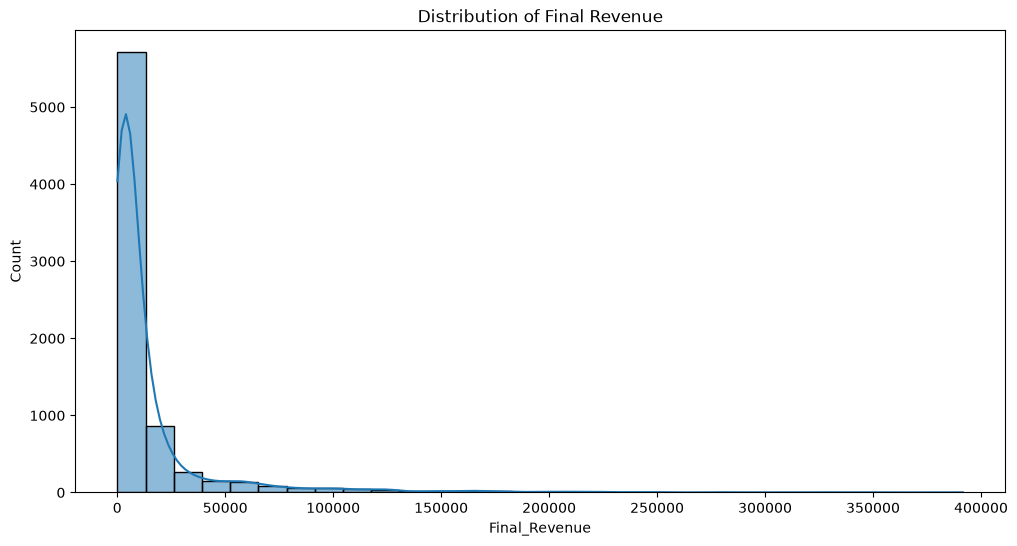

In [14]:
plt.figure(figsize=(12, 6))
plt.title("Distribution of Final Revenue")
sns.histplot(data = sales, x='Final_Revenue', bins=30, kde=True)

<Axes: title={'center': 'Distribution of Rating'}, xlabel='Rating', ylabel='Count'>

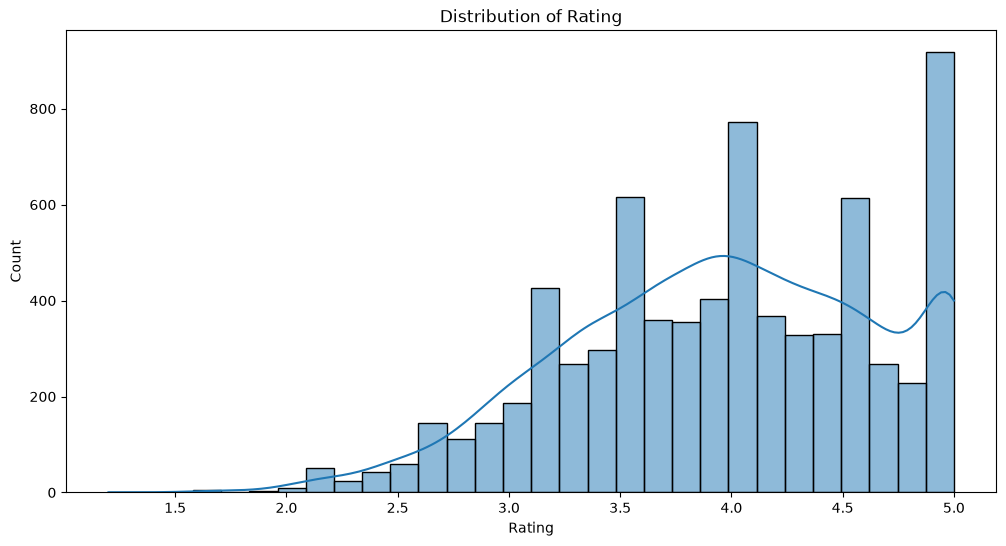

In [15]:
plt.figure(figsize=(12, 6))
plt.title("Distribution of Rating")
sns.histplot(data = sales, x='Rating', bins=30, kde=True)

C:\Users\hisha\AppData\Local\Temp\ipykernel_3908\1439261623.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


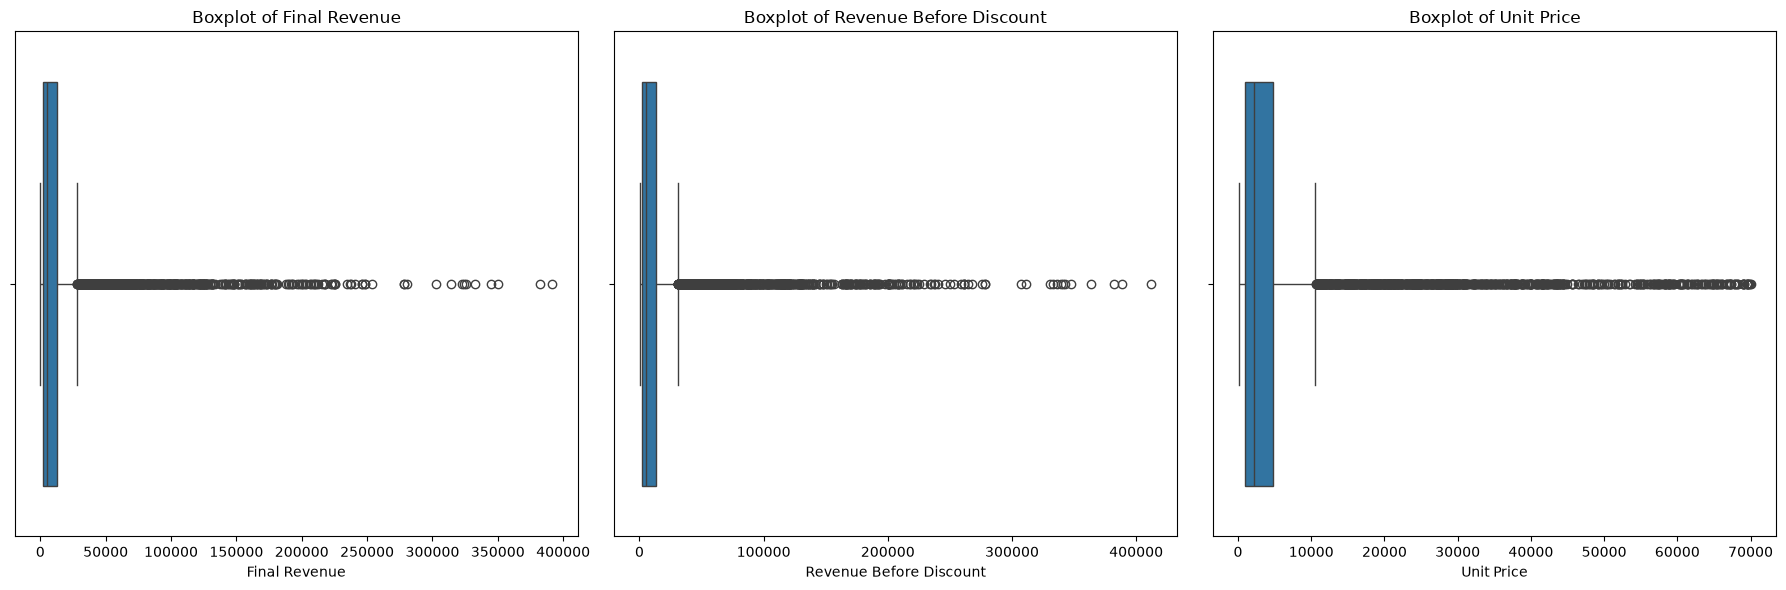

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True, constrained_layout=True)
sns.boxplot(data=sales, x='Final_Revenue', ax=axes[0])
sns.boxplot(data=sales, x='Revenue_Before_Discount', ax=axes[1])
sns.boxplot(data=sales, x='Unit_Price', ax=axes[2])

axes[0].set_title('Boxplot of Final Revenue')
axes[1].set_title('Boxplot of Revenue Before Discount')
axes[2].set_title('Boxplot of Unit Price')

axes[0].set_xlabel('Final Revenue')
axes[1].set_xlabel('Revenue Before Discount')
axes[2].set_xlabel('Unit Price')

fig.tight_layout()


C:\Users\hisha\AppData\Local\Temp\ipykernel_3908\1802660317.py:31: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


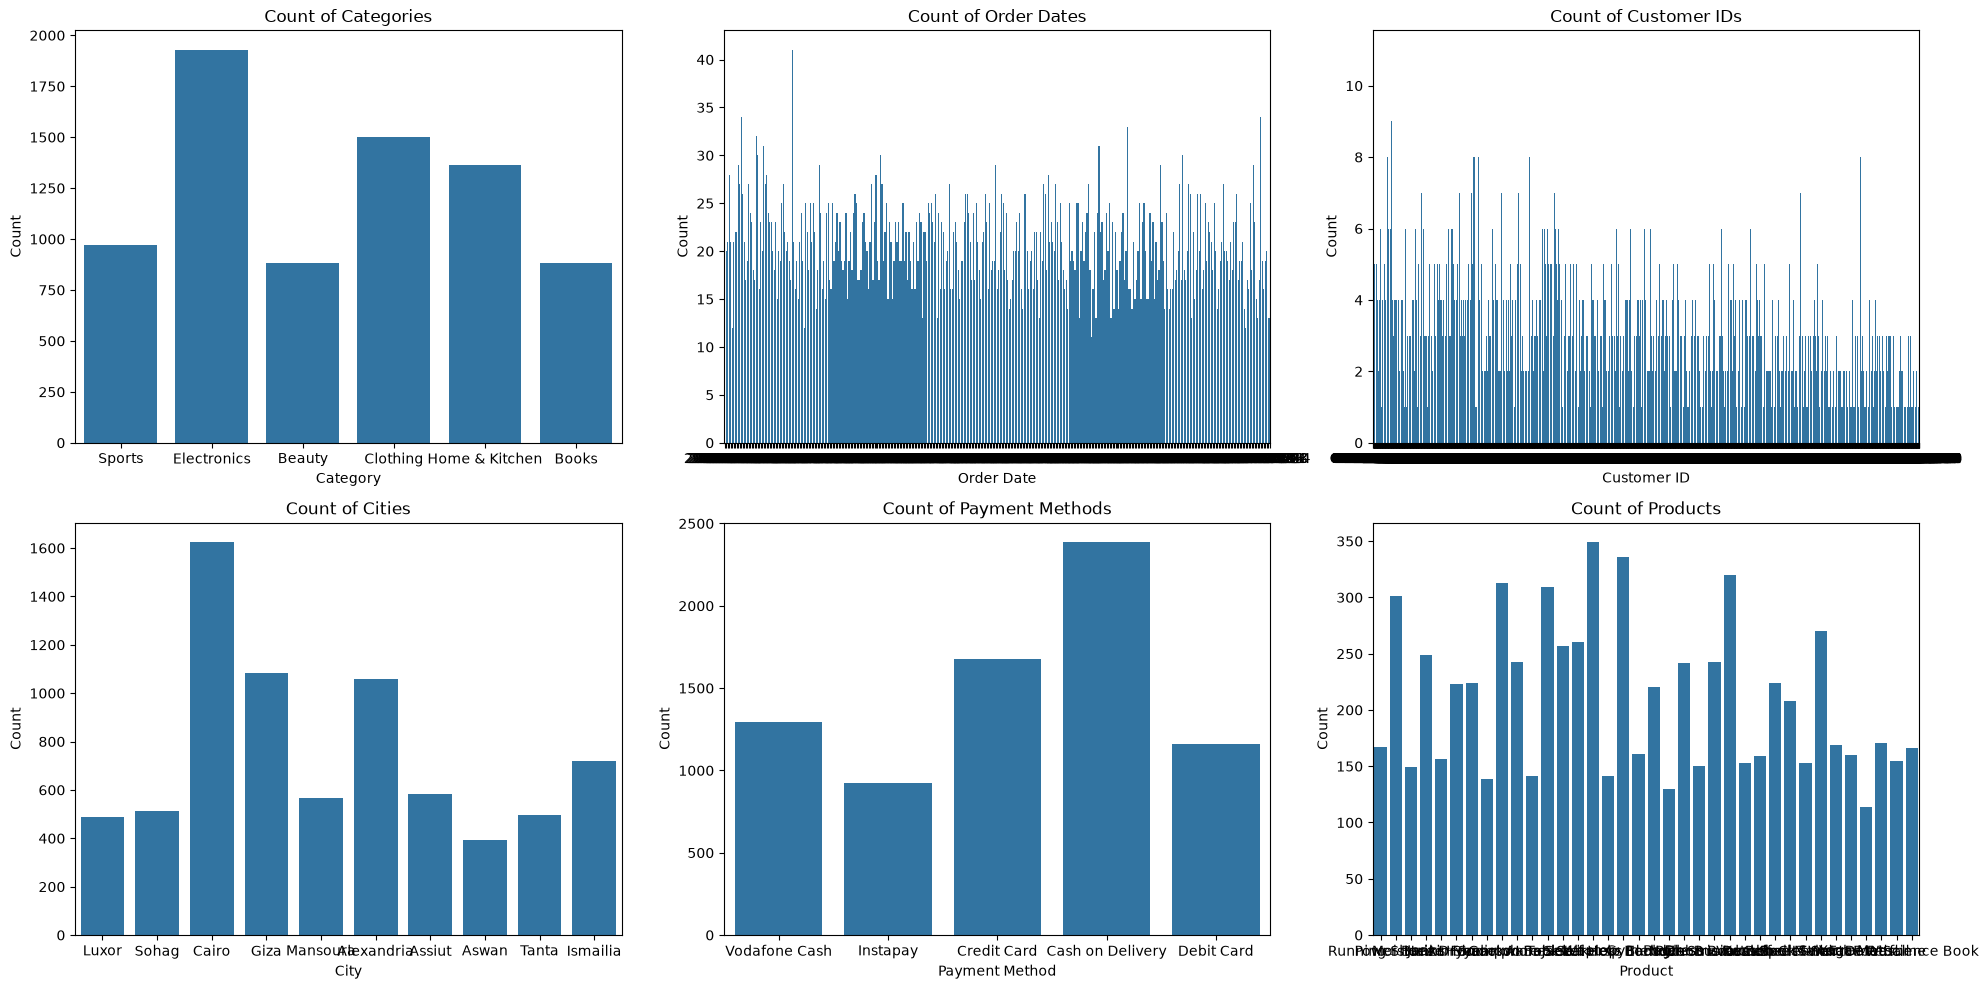

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(20, 10),constrained_layout=True)

sns.countplot(data=sales, x='Category', ax=axes[0, 0])
sns.countplot(data=sales, x='Order_Date', ax=axes[0, 1])
sns.countplot(data=sales, x='Customer_ID', ax=axes[0, 2])
sns.countplot(data=sales, x='City', ax=axes[1, 0])
sns.countplot(data=sales, x='Payment_Method', ax=axes[1, 1])
sns.countplot(data=sales, x='Product', ax=axes[1, 2])

axes[0, 0].set_title('Count of Categories')
axes[0, 1].set_title('Count of Order Dates')
axes[0, 2].set_title('Count of Customer IDs')
axes[1, 0].set_title('Count of Cities')
axes[1, 1].set_title('Count of Payment Methods')
axes[1, 2].set_title('Count of Products')

axes[0, 0].set_xlabel('Category')
axes[0, 1].set_xlabel('Order Date')
axes[0, 2].set_xlabel('Customer ID')
axes[1, 0].set_xlabel('City')
axes[1, 1].set_xlabel('Payment Method')
axes[1, 2].set_xlabel('Product')

axes[0, 0].set_ylabel('Count')
axes[0, 1].set_ylabel('Count')
axes[0, 2].set_ylabel('Count')
axes[1, 0].set_ylabel('Count')
axes[1, 1].set_ylabel('Count')
axes[1, 2].set_ylabel('Count')

fig.tight_layout()

<Axes: xlabel='Discount', ylabel='Final_Revenue'>

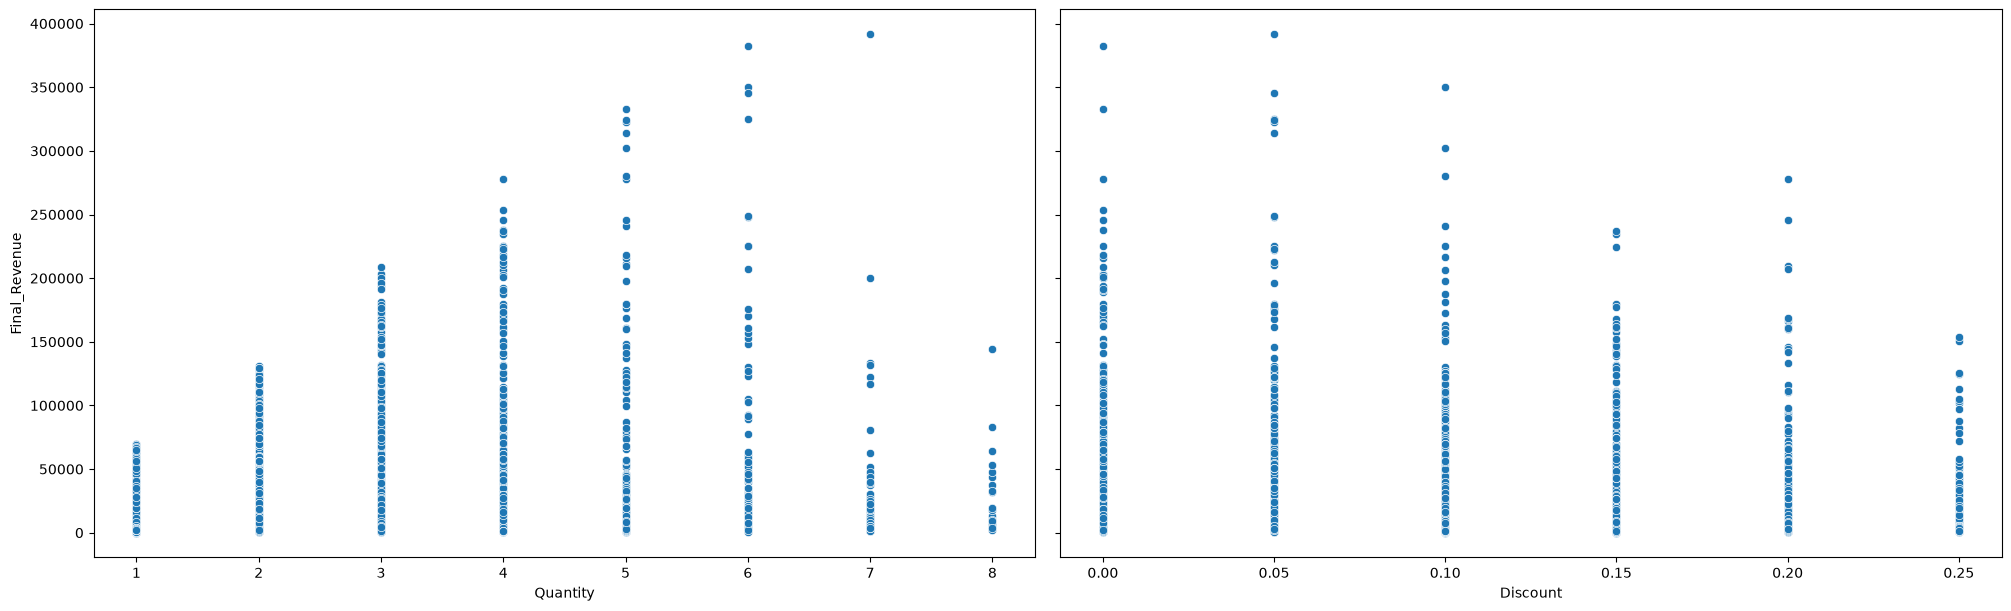

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(20, 6),sharey=True, constrained_layout=True)
sns.scatterplot(data=sales, x='Quantity', y='Final_Revenue', ax=axes[0])
sns.scatterplot(data=sales, x='Discount', y='Final_Revenue', ax=axes[1])

<Axes: xlabel='Category', ylabel='Final_Revenue'>

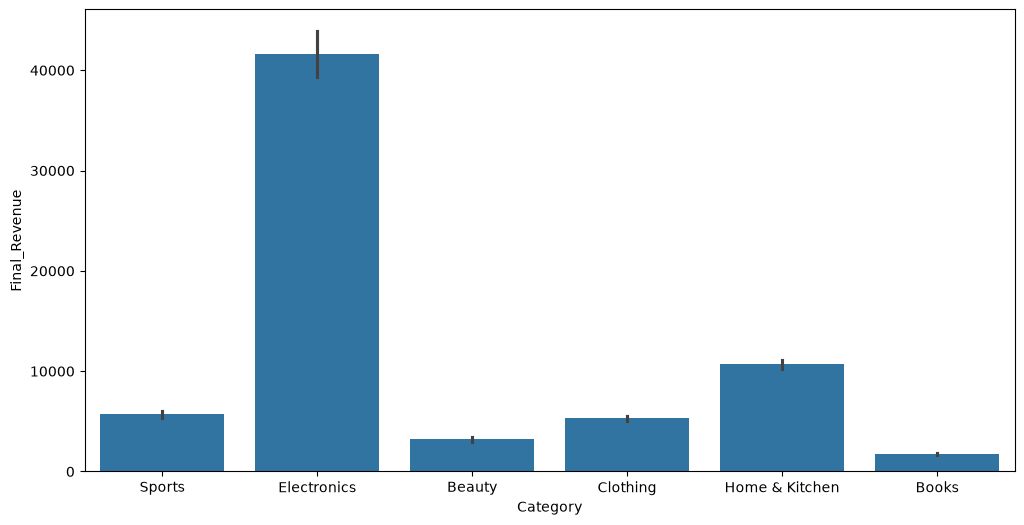

In [19]:
plt.figure(figsize=(12, 6))
sns.barplot(data=sales, x='Category', y='Final_Revenue')

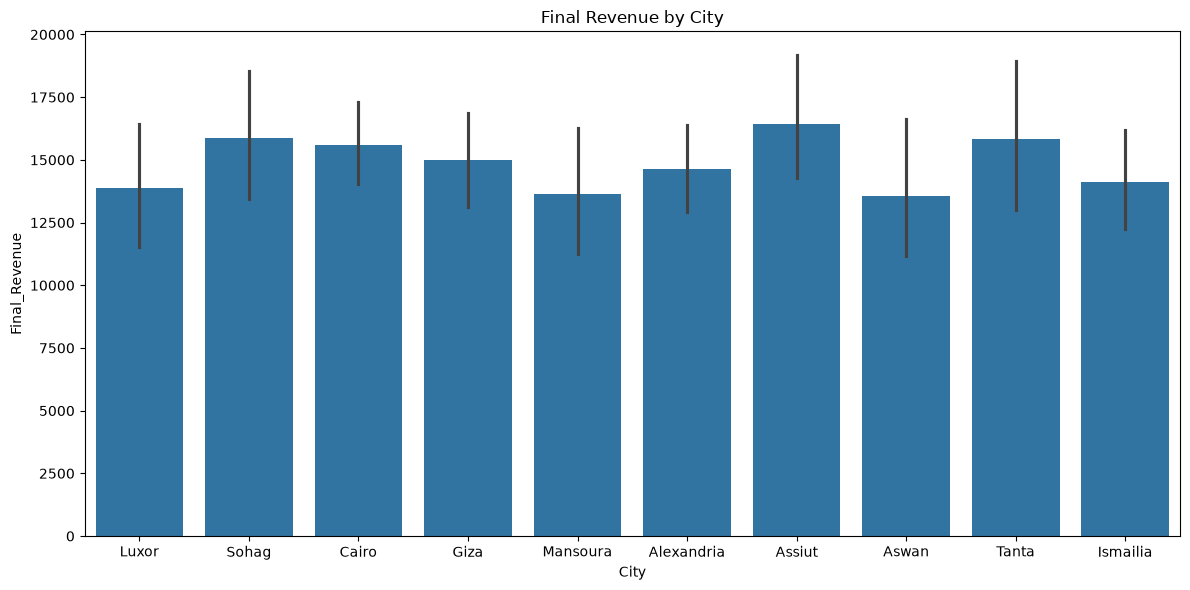

In [20]:
plt.figure(figsize=(12, 6))
sns.barplot(data=sales, x='City', y='Final_Revenue')

plt.title("Final Revenue by City")
plt.tight_layout()

Text(0.5, 1.0, 'Final Revenue vs Rating')

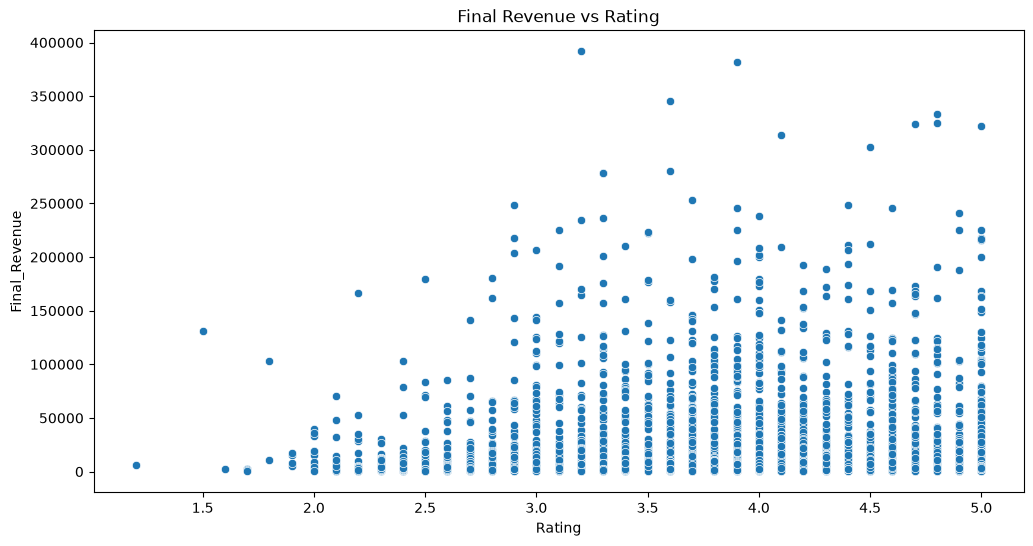

In [21]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=sales, x='Rating', y='Final_Revenue')

plt.title("Final Revenue vs Rating")

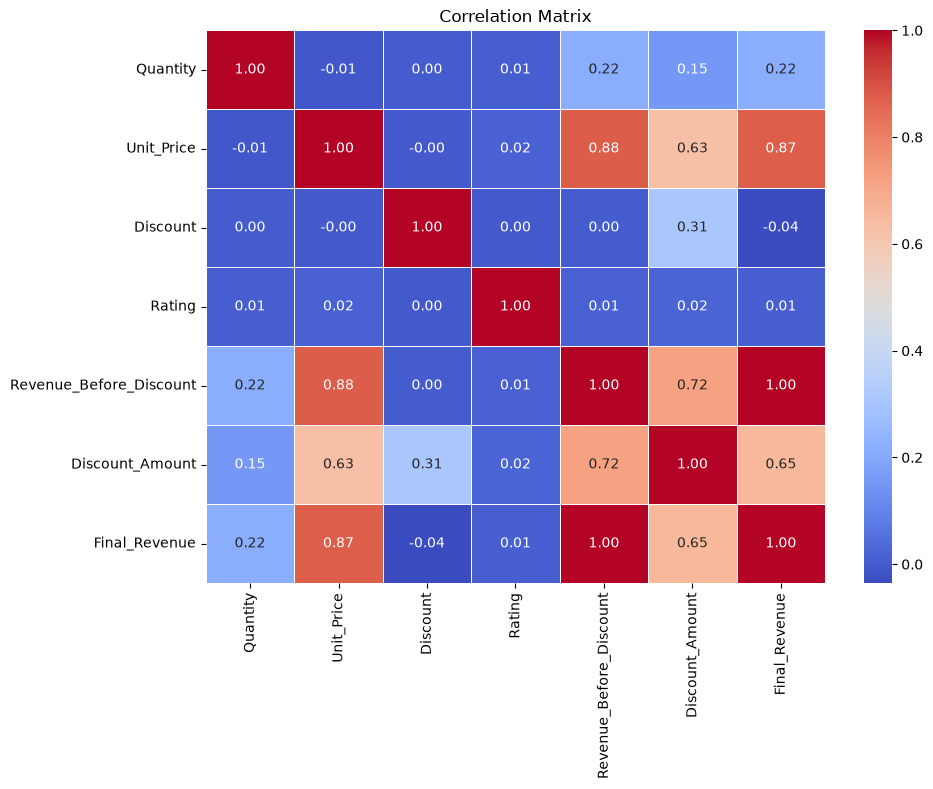

In [22]:
correlation_matrix = sales[numerical_columns].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix")
plt.tight_layout()

In [23]:
sales.groupby('Category')['Final_Revenue'].sum().sort_values(ascending=False)

Category
Electronics       80211922.5
Home & Kitchen    14565786.0
Clothing           7951316.0
Sports             5523785.5
Beauty             2824800.0
Books              1546333.0
Name: Final_Revenue, dtype: float64

In [24]:
sales.groupby('City')['Final_Revenue'].sum().sort_values(ascending=False)

City
Cairo         25331760.0
Giza          16266872.5
Alexandria    15470987.0
Ismailia      10159401.0
Assiut         9560786.5
Sohag          8137919.5
Tanta          7877595.5
Mansoura       7744755.0
Luxor          6755790.0
Aswan          5318076.0
Name: Final_Revenue, dtype: float64

In [25]:
sales["Payment_Method"].value_counts().sort_values(ascending=False)

Payment_Method
Cash on Delivery    2386
Credit Card         1675
Vodafone Cash       1294
Debit Card          1158
Instapay             922
Name: count, dtype: int64

In [26]:
average_order_value = sales["Final_Revenue"].mean()
print(f"Average Order Value = {average_order_value:.2f}")

Average Order Value = 14966.64


Text(0.5, 1.0, 'Final Revenue vs Discount')

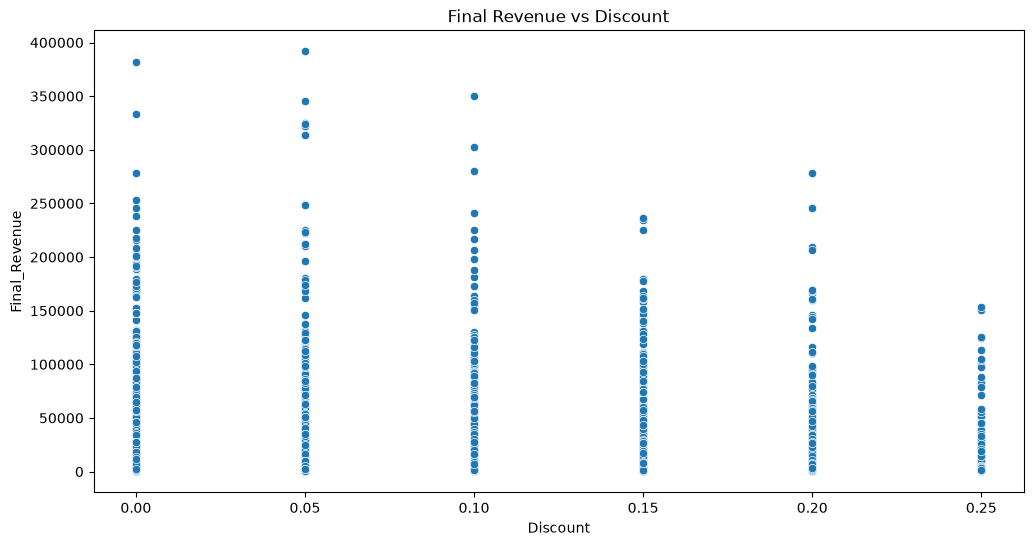

In [27]:
plt.figure(figsize=(12, 6))
sns.scatterplot(data=sales, x='Discount', y='Final_Revenue')

plt.title("Final Revenue vs Discount")

Phase 3 : Data Cleaning

In [28]:
sales_cleaned = sales.copy()

In [29]:
sales_cleaned.isna().sum()

Order_ID                     0
Order_Date                   0
Customer_ID                  0
Category                     0
Product                      0
Quantity                     0
Unit_Price                   0
Discount                    61
City                         0
Payment_Method              90
Rating                     188
Order_Status                 0
Revenue_Before_Discount      0
Discount_Amount              0
Final_Revenue                0
dtype: int64

In [30]:
missing_values_count = sales_cleaned.isna().sum().sum()
total_cells = sales_cleaned.shape[0] * sales_cleaned.shape[1]
missing_value_percentage = (missing_values_count / total_cells) * 100

print(f"Missing values: {missing_values_count}")
print(f"Missing values percentage of all cells: {missing_value_percentage:.2f}%")

Missing values: 339
Missing values percentage of all cells: 0.30%


In [31]:
# Detect exact duplicate rows before filling missing values.
duplicate_count = sales_cleaned.duplicated().sum()
print(f"Exact duplicate rows: {duplicate_count}")

duplicate_mask = sales_cleaned.duplicated(keep=False)
sales_cleaned.loc[duplicate_mask].sort_values("Order_ID").head(20)

Exact duplicate rows: 25


,Order_ID,Order_Date,Customer_ID,Category,Product,Quantity,Unit_Price,Discount,City,Payment_Method,Rating,Order_Status,Revenue_Before_Discount,Discount_Amount,Final_Revenue
70,ORD-000102,2025-08-16,CUST-11560,Beauty,Hair Dryer,3,1360,0.05,Cairo,Debit Card,4.5,Delivered,4080,204.0,3876.0
1060,ORD-000102,2025-08-16,CUST-11560,Beauty,Hair Dryer,3,1360,0.05,Cairo,Debit Card,4.5,Delivered,4080,204.0,3876.0
385,ORD-000430,2025-12-03,CUST-11681,Electronics,Wireless Earbuds,3,4440,0.15,Tanta,Credit Card,3.9,Delivered,13320,1998.0,11322.0
6789,ORD-000430,2025-12-03,CUST-11681,Electronics,Wireless Earbuds,3,4440,0.15,Tanta,Credit Card,3.9,Delivered,13320,1998.0,11322.0
464,ORD-000466,2025-09-30,CUST-11825,Home & Kitchen,Coffee Maker,3,1140,0.10,Tanta,Credit Card,3.1,Delivered,3420,342.0,3078.0
706,ORD-000466,2025-09-30,CUST-11825,Home & Kitchen,Coffee Maker,3,1140,0.10,Tanta,Credit Card,3.1,Delivered,3420,342.0,3078.0
428,ORD-000971,2025-02-11,CUST-11153,Beauty,Shampoo,1,280,0.15,Cairo,Cash on Delivery,3.8,Delivered,280,42.0,238.0
5519,ORD-000971,2025-02-11,CUST-11153,Beauty,Shampoo,1,280,0.15,Cairo,Cash on Delivery,3.8,Delivered,280,42.0,238.0
807,ORD-001447,2025-04-02,CUST-11365,Beauty,Face Wash,4,830,0.05,Luxor,Instapay,3.8,Delivered,3320,166.0,3154.0
5840,ORD-001447,2025-04-02,CUST-11365,Beauty,Face Wash,4,830,0.05,Luxor,Instapay,3.8,Delivered,3320,166.0,3154.0


In [32]:
# Remove only exact full-row duplicates.
rows_before = len(sales_cleaned)
sales_cleaned = sales_cleaned.drop_duplicates().copy()
rows_after = len(sales_cleaned)

print(f"Rows before removing duplicates: {rows_before}")
print(f"Rows after removing duplicates: {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")

Rows before removing duplicates: 7525
Rows after removing duplicates: 7500
Rows removed: 25


In [33]:
# Fill missing payment methods with the most frequent category.
payment_method_mode = sales_cleaned["Payment_Method"].mode()[0]
sales_cleaned["Payment_Method"] = sales_cleaned["Payment_Method"].fillna(payment_method_mode)

# Recover the missing discount RATE from the existing monetary discount amount.
# Discount is stored as a fraction (for example, 0.10 means 10%).
derived_discount_rate = (
    sales_cleaned["Discount_Amount"] / sales_cleaned["Revenue_Before_Discount"]
)
sales_cleaned["Discount"] = sales_cleaned["Discount"].fillna(derived_discount_rate)

# Fill missing ratings with the median, which is less sensitive to extreme values than the mean.
rating_median = sales_cleaned["Rating"].median()
sales_cleaned["Rating"] = sales_cleaned["Rating"].fillna(rating_median)

In [34]:
sales_cleaned.isna().sum()

Order_ID                   0
Order_Date                 0
Customer_ID                0
Category                   0
Product                    0
Quantity                   0
Unit_Price                 0
Discount                   0
City                       0
Payment_Method             0
Rating                     0
Order_Status               0
Revenue_Before_Discount    0
Discount_Amount            0
Final_Revenue              0
dtype: int64

In [35]:
# Check for any remaining exact duplicates after cleaning.
sales_cleaned.duplicated().sum()

np.int64(0)

In [36]:
# Verify the recovered discount rates are within the expected 0–25% range.
sales_cleaned["Discount"].describe()

count    7500.000000
mean        0.082933
std         0.072540
min         0.000000
25%         0.000000
50%         0.100000
75%         0.150000
max         0.250000
Name: Discount, dtype: float64

In [37]:
# Check for invalid values in key numeric columns.
invalid_checks = {
    "Quantity <= 0": (sales_cleaned["Quantity"] <= 0).sum(),
    "Unit_Price <= 0": (sales_cleaned["Unit_Price"] <= 0).sum(),
    "Rating outside 1–5": ((sales_cleaned["Rating"] < 1) | (sales_cleaned["Rating"] > 5)).sum(),
    "Discount outside 0–1": ((sales_cleaned["Discount"] < 0) | (sales_cleaned["Discount"] > 1)).sum(),
    "Negative Final_Revenue": (sales_cleaned["Final_Revenue"] < 0).sum()
}
pd.Series(invalid_checks, name="Invalid row count")

Quantity <= 0             0
Unit_Price <= 0           0
Rating outside 1–5        0
Discount outside 0–1      0
Negative Final_Revenue    0
Name: Invalid row count, dtype: int64

In [38]:
sales_cleaned["Order_Date"] = pd.to_datetime(sales_cleaned["Order_Date"], errors="coerce")
sales_cleaned.dtypes

Order_ID                              str
Order_Date                 datetime64[us]
Customer_ID                           str
Category                              str
Product                               str
Quantity                            int64
Unit_Price                          int64
Discount                          float64
City                                  str
Payment_Method                        str
Rating                            float64
Order_Status                          str
Revenue_Before_Discount             int64
Discount_Amount                   float64
Final_Revenue                     float64
dtype: object

In [39]:
print("Original shape:", sales.shape)
print("Clean shape:", sales_cleaned.shape)
print("Remaining missing values:", sales_cleaned.isna().sum().sum())
print("Remaining duplicates:", sales_cleaned.duplicated().sum())

Original shape: (7525, 15)
Clean shape: (7500, 15)
Remaining missing values: 0
Remaining duplicates: 0


In [40]:
# Confirm each Order_ID represents one order.
print("Unique Order IDs:", sales_cleaned["Order_ID"].nunique())
print("Rows in cleaned dataset:", len(sales_cleaned))

Unique Order IDs: 7500
Rows in cleaned dataset: 7500


In [41]:
# Cleaning summary table
cleaning_summary = pd.DataFrame({
    "Issue": [
        "Missing Payment_Method",
        "Missing Discount",
        "Missing Rating",
        "Exact duplicate rows",
        "Order_Date data type"
    ],
    "Action": [
        "Filled with mode",
        "Derived from Discount_Amount / Revenue_Before_Discount",
        "Filled with median",
        "Removed exact full-row duplicates",
        "Converted to datetime"
    ],
    "Reason": [
        "Categorical value; mode provides the most frequent category",
        "The original Discount column is a rate, while Discount_Amount is monetary",
        "Median is robust to skew and extreme values",
        "Exact repeated records should not be counted twice",
        "Enables reliable date-based analysis"
    ]
})
cleaning_summary

,Issue,Action,Reason
0,Missing Payment_Method,Filled with mode,Categorical value; mode provides the most freq...
1,Missing Discount,Derived from Discount_Amount / Revenue_Before_...,"The original Discount column is a rate, while ..."
2,Missing Rating,Filled with median,Median is robust to skew and extreme values
3,Exact duplicate rows,Removed exact full-row duplicates,Exact repeated records should not be counted t...
4,Order_Date data type,Converted to datetime,Enables reliable date-based analysis


In [42]:
# Inspect rows with non-positive quantities, if any.
sales_cleaned.loc[sales_cleaned["Quantity"] <= 0]

,Order_ID,Order_Date,Customer_ID,Category,Product,Quantity,Unit_Price,Discount,City,Payment_Method,Rating,Order_Status,Revenue_Before_Discount,Discount_Amount,Final_Revenue


In [43]:
# Final cleaned-data validation
assert sales_cleaned.isna().sum().sum() == 0, "Missing values remain."
assert sales_cleaned.duplicated().sum() == 0, "Duplicate rows remain."
assert sales_cleaned["Order_Date"].dtype.kind == "M", "Order_Date is not datetime."

print("Data cleaning validation passed.")

Data cleaning validation passed.


In [44]:
sales_cleaned.head()

,Order_ID,Order_Date,Customer_ID,Category,Product,Quantity,Unit_Price,Discount,City,Payment_Method,Rating,Order_Status,Revenue_Before_Discount,Discount_Amount,Final_Revenue
0,ORD-005874,2025-10-23,CUST-12091,Sports,Running Shoes,3,4320,0.10,Luxor,Vodafone Cash,4.4,Delivered,12960,1296.0,11664.0
1,ORD-001411,2025-04-10,CUST-12192,Electronics,Power Bank,3,1240,0.00,Sohag,Instapay,4.0,Delivered,3720,0.0,3720.0
2,ORD-002686,2025-12-09,CUST-11769,Electronics,Power Bank,5,1670,0.00,Cairo,Vodafone Cash,3.0,Delivered,8350,0.0,8350.0
3,ORD-005556,2025-10-29,CUST-10022,Beauty,Moisturizer,4,840,0.05,Giza,Credit Card,4.2,Delivered,3360,168.0,3192.0
4,ORD-003827,2025-01-16,CUST-11113,Clothing,Jeans,5,740,0.05,Mansoura,Cash on Delivery,4.8,Delivered,3700,185.0,3515.0


## Phase 4: Business Analysis


In [45]:
total_revenue = sales_cleaned["Final_Revenue"].sum()
print(f"Total Revenue = {total_revenue:.2f}")

Total Revenue = 112342110.50


In [46]:
# Each row represents one order after confirming Order_ID uniqueness.
average_order_value = sales_cleaned["Final_Revenue"].mean()
print(f"Average Order Value = {average_order_value:,.2f}")

Average Order Value = 14,978.95


In [47]:
total_orders = sales_cleaned["Order_ID"].nunique()
print(f"Total Number of Orders = {total_orders:,}")

Total Number of Orders = 7,500


In [48]:
total_sold_units = sales_cleaned["Quantity"].sum()
print(f"Total Sold Units = {total_sold_units} unit")

Total Sold Units = 21017 unit


In [49]:
sales_cleaned.groupby('Category')['Final_Revenue'].sum().sort_values(ascending=False)

Category
Electronics       79989973.0
Home & Kitchen    14533961.5
Clothing           7940362.5
Sports             5521631.5
Beauty             2812372.0
Books              1543810.0
Name: Final_Revenue, dtype: float64

In [50]:
sales_cleaned.groupby('Category')['Quantity'].sum().sort_values(ascending=False)

Category
Electronics       5414
Clothing          4259
Home & Kitchen    3758
Sports            2620
Books             2512
Beauty            2454
Name: Quantity, dtype: int64

In [51]:
sales_cleaned.groupby('Category')[['Quantity','Final_Revenue']].sum().sort_values(by='Final_Revenue', ascending=False)

,Quantity,Final_Revenue
Category,,
Electronics,5414,79989973.0
Home & Kitchen,3758,14533961.5
Clothing,4259,7940362.5
Sports,2620,5521631.5
Beauty,2454,2812372.0
Books,2512,1543810.0


In [52]:
unique_customers = sales_cleaned['Customer_ID'].nunique()
print(f"Total Unique Customers = {unique_customers}")

Total Unique Customers = 2383


In [53]:
sales_cleaned['Customer_ID'].value_counts()

Customer_ID
CUST-11825    10
CUST-10030    10
CUST-11741     9
CUST-10787     9
CUST-10849     9
              ..
CUST-10872     1
CUST-11742     1
CUST-11685     1
CUST-10078     1
CUST-11059     1
Name: count, Length: 2383, dtype: int64

In [54]:
sales_cleaned.groupby('Customer_ID')['Final_Revenue'].mean().sort_values(ascending=False)

Customer_ID
CUST-10422    238000.0
CUST-11465    233814.0
CUST-11204    159840.0
CUST-12170    145777.5
CUST-12475    143522.5
                ...   
CUST-11168       340.0
CUST-12211       330.0
CUST-11792       330.0
CUST-10071       322.5
CUST-11808       322.5
Name: Final_Revenue, Length: 2383, dtype: float64

In [55]:
sales_cleaned.groupby('Customer_ID')['Final_Revenue'].sum().sort_values(ascending=False)

Customer_ID
CUST-11465    467628.0
CUST-11117    430963.5
CUST-10609    423288.5
CUST-11982    421180.0
CUST-12389    404007.0
                ...   
CUST-11168       340.0
CUST-11792       330.0
CUST-12211       330.0
CUST-11808       322.5
CUST-10071       322.5
Name: Final_Revenue, Length: 2383, dtype: float64

In [56]:
total_discount_amount = sales_cleaned["Discount_Amount"].sum()
print(f"Total Discount Amount = {total_discount_amount:,.2f}")

Total Discount Amount = 10,187,929.50


In [57]:
average_discount_amount = sales_cleaned["Discount_Amount"].mean()
average_discount_rate = sales_cleaned["Discount"].mean()

print(f"Average Discount Amount per Order = {average_discount_amount:,.2f}")
print(f"Average Discount Rate = {average_discount_rate:.2%}")

Average Discount Amount per Order = 1,358.39
Average Discount Rate = 8.29%


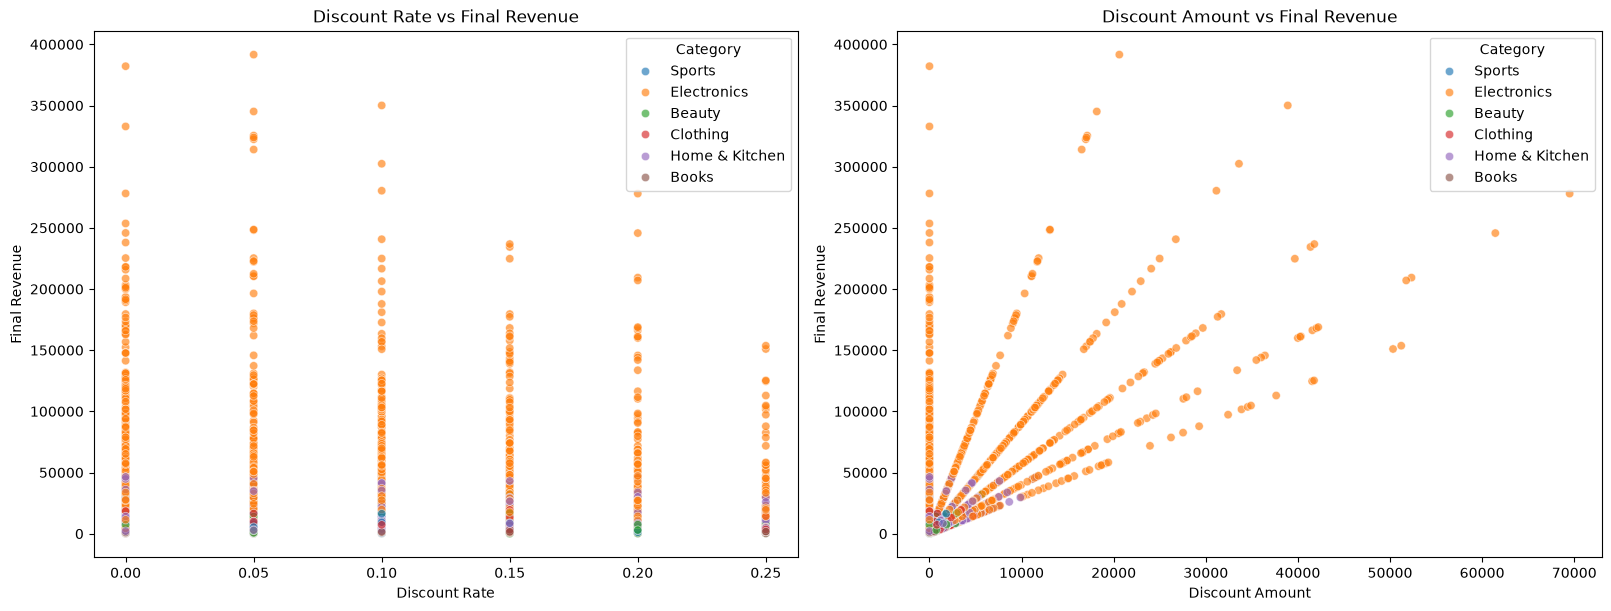

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

sns.scatterplot(
    data=sales_cleaned,
    x="Discount",
    y="Final_Revenue",
    hue="Category",
    alpha=0.65,
    ax=axes[0]
)
axes[0].set_title("Discount Rate vs Final Revenue")
axes[0].set_xlabel("Discount Rate")
axes[0].set_ylabel("Final Revenue")

sns.scatterplot(
    data=sales_cleaned,
    x="Discount_Amount",
    y="Final_Revenue",
    hue="Category",
    alpha=0.65,
    ax=axes[1]
)
axes[1].set_title("Discount Amount vs Final Revenue")
axes[1].set_xlabel("Discount Amount")
axes[1].set_ylabel("Final Revenue")

plt.show()

In [59]:
# Count orders by status, not units.
orders_by_status = (
    sales_cleaned.groupby("Order_Status")["Order_ID"]
    .nunique()
    .sort_values(ascending=False)
)
orders_by_status

Order_Status
Delivered    6848
Cancelled     302
Shipped       217
Returned      133
Name: Order_ID, dtype: int64

In [60]:
status_percentage = (orders_by_status / total_orders * 100).round(2)
status_summary = pd.DataFrame({
    "Orders": orders_by_status,
    "Percentage": status_percentage
})
status_summary

,Orders,Percentage
Order_Status,,
Delivered,6848,91.31
Cancelled,302,4.03
Shipped,217,2.89
Returned,133,1.77


In [61]:
# Payment method analysis: number of orders and revenue.
payment_summary = (
    sales_cleaned.groupby("Payment_Method")
    .agg(
        Orders=("Order_ID", "nunique"),
        Total_Revenue=("Final_Revenue", "sum"),
        Average_Order_Value=("Final_Revenue", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)
payment_summary

,Orders,Total_Revenue,Average_Order_Value
Payment_Method,,,
Cash on Delivery,2471,37226097.5,15065.195265
Credit Card,1671,24090793.0,14416.991622
Vodafone Cash,1287,21080213.0,16379.341880
Debit Card,1153,16026865.5,13900.143539
Instapay,918,13918141.5,15161.374183


In [62]:
# Revenue by order status. Interpret this carefully: cancelled/returned orders
# may still have revenue values in the source data.
revenue_by_status = (
    sales_cleaned.groupby("Order_Status")["Final_Revenue"]
    .sum()
    .sort_values(ascending=False)
)
revenue_by_status

Order_Status
Delivered    102294904.5
Cancelled      4250739.0
Shipped        3166208.0
Returned       2630259.0
Name: Final_Revenue, dtype: float64

In [63]:
city_summary = (
    sales_cleaned.groupby("City")
    .agg(
        Orders=("Order_ID", "nunique"),
        Total_Revenue=("Final_Revenue", "sum"),
        Average_Order_Value=("Final_Revenue", "mean")
    )
    .sort_values("Total_Revenue", ascending=False)
)
city_summary

,Orders,Total_Revenue,Average_Order_Value
City,,,
Cairo,1621,25319979.0,15619.974707
Giza,1082,16261072.0,15028.717190
Alexandria,1055,15421889.0,14617.904265
Ismailia,716,10000378.5,13967.009078
Assiut,580,9551181.5,16467.554310
Sohag,512,8133623.5,15885.983398
Tanta,494,7848027.5,15886.695344
Mansoura,567,7743630.0,13657.195767
Luxor,481,6744253.5,14021.317048


In [64]:
city_summary.sort_values("Orders", ascending=False)

,Orders,Total_Revenue,Average_Order_Value
City,,,
Cairo,1621,25319979.0,15619.974707
Giza,1082,16261072.0,15028.717190
Alexandria,1055,15421889.0,14617.904265
Ismailia,716,10000378.5,13967.009078
Assiut,580,9551181.5,16467.554310
Mansoura,567,7743630.0,13657.195767
Sohag,512,8133623.5,15885.983398
Tanta,494,7848027.5,15886.695344
Luxor,481,6744253.5,14021.317048


## Phase 5: Final Visualization & Business Insights


In [65]:
# Final KPIs — calculated from the cleaned dataset only.
total_revenue = sales_cleaned["Final_Revenue"].sum()
total_orders = sales_cleaned["Order_ID"].nunique()
average_order_value = sales_cleaned["Final_Revenue"].mean()
total_sold_units = sales_cleaned["Quantity"].sum()
total_discount_amount = sales_cleaned["Discount_Amount"].sum()
unique_customers = sales_cleaned["Customer_ID"].nunique()

kpis = pd.Series({
    "Total Revenue": total_revenue,
    "Total Orders": total_orders,
    "Average Order Value": average_order_value,
    "Total Units Sold": total_sold_units,
    "Total Discount Amount": total_discount_amount,
    "Unique Customers": unique_customers
}, name="Value")

kpis

Total Revenue            1.123421e+08
Total Orders             7.500000e+03
Average Order Value      1.497895e+04
Total Units Sold         2.101700e+04
Total Discount Amount    1.018793e+07
Unique Customers         2.383000e+03
Name: Value, dtype: float64

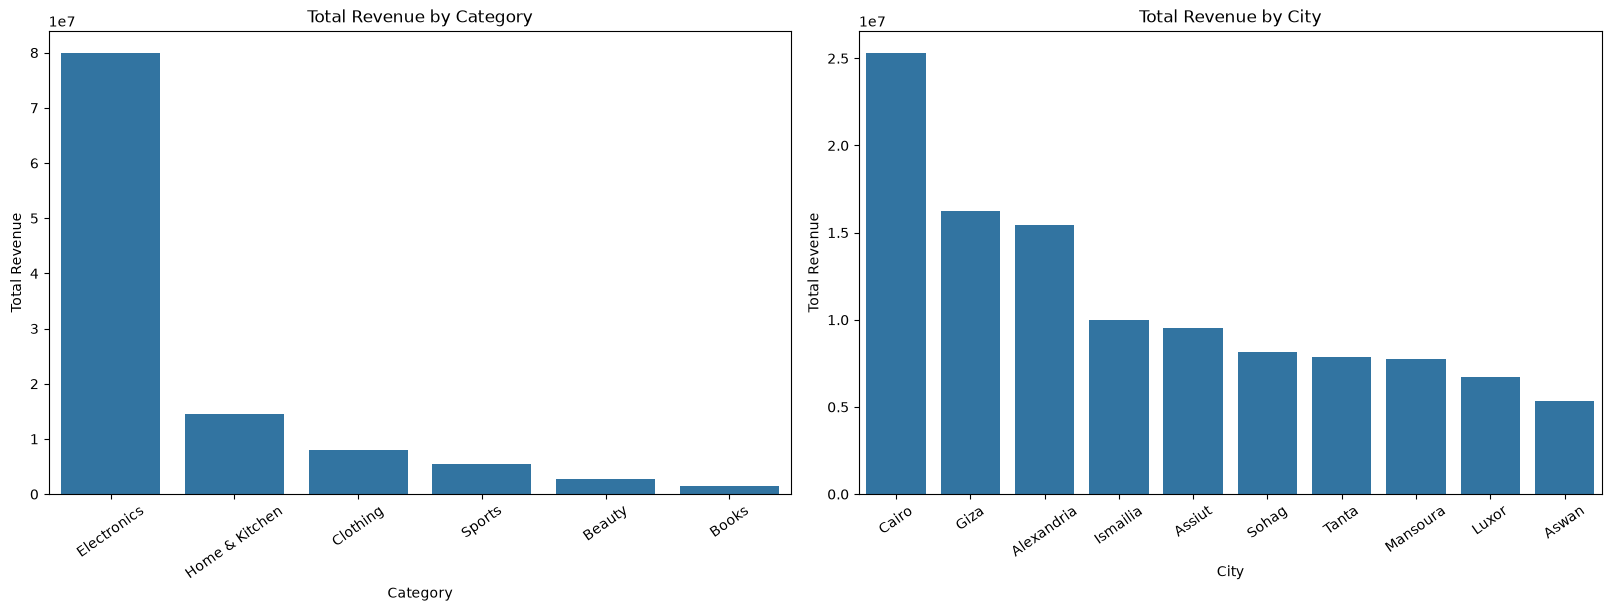

In [66]:
# Aggregate with SUM before plotting: seaborn.barplot otherwise shows a mean.
revenue_by_category = (
    sales_cleaned.groupby("Category", as_index=False)["Final_Revenue"]
    .sum()
    .sort_values("Final_Revenue", ascending=False)
)
revenue_by_city = (
    sales_cleaned.groupby("City", as_index=False)["Final_Revenue"]
    .sum()
    .sort_values("Final_Revenue", ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)

sns.barplot(data=revenue_by_category, x="Category", y="Final_Revenue", ax=axes[0])
axes[0].set_title("Total Revenue by Category")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Total Revenue")
axes[0].tick_params(axis="x", rotation=35)

sns.barplot(data=revenue_by_city, x="City", y="Final_Revenue", ax=axes[1])
axes[1].set_title("Total Revenue by City")
axes[1].set_xlabel("City")
axes[1].set_ylabel("Total Revenue")
axes[1].tick_params(axis="x", rotation=35)

plt.show()

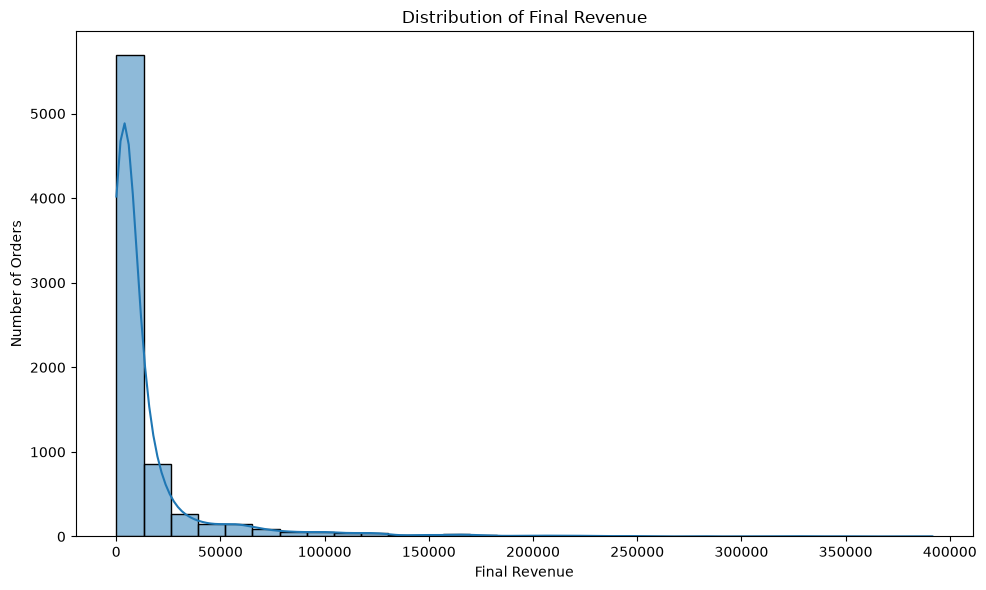

In [67]:
plt.figure(figsize=(10, 6))
sns.histplot(data=sales_cleaned, x="Final_Revenue", bins=30, kde=True)
plt.title("Distribution of Final Revenue")
plt.xlabel("Final Revenue")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

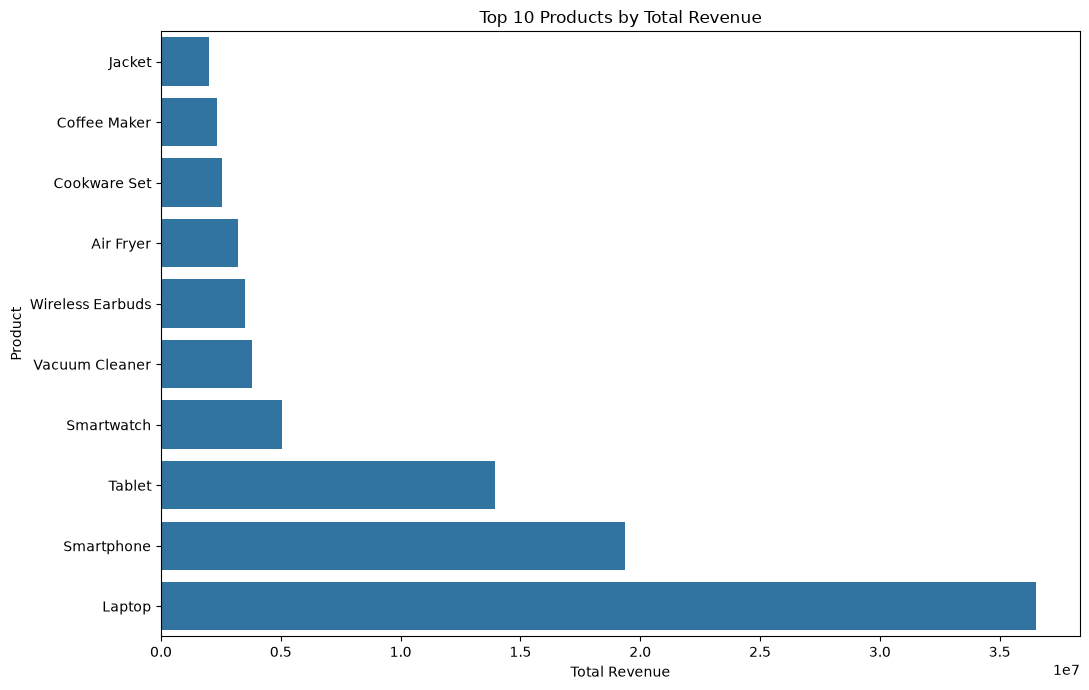

In [68]:
top_10_products = (
    sales_cleaned.groupby("Product", as_index=False)["Final_Revenue"]
    .sum()
    .nlargest(10, "Final_Revenue")
    .sort_values("Final_Revenue", ascending=True)
)

plt.figure(figsize=(11, 7))
sns.barplot(data=top_10_products, x="Final_Revenue", y="Product")
plt.title("Top 10 Products by Total Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

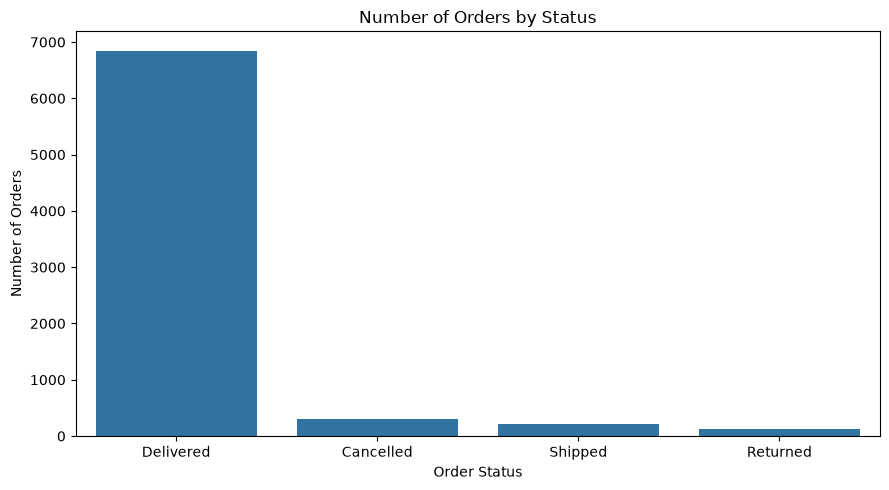

In [69]:
# Order status distribution: count unique orders, not revenue or quantity.
plt.figure(figsize=(9, 5))
status_plot = orders_by_status.rename_axis("Order_Status").reset_index(name="Orders")
sns.barplot(data=status_plot, x="Order_Status", y="Orders")
plt.title("Number of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

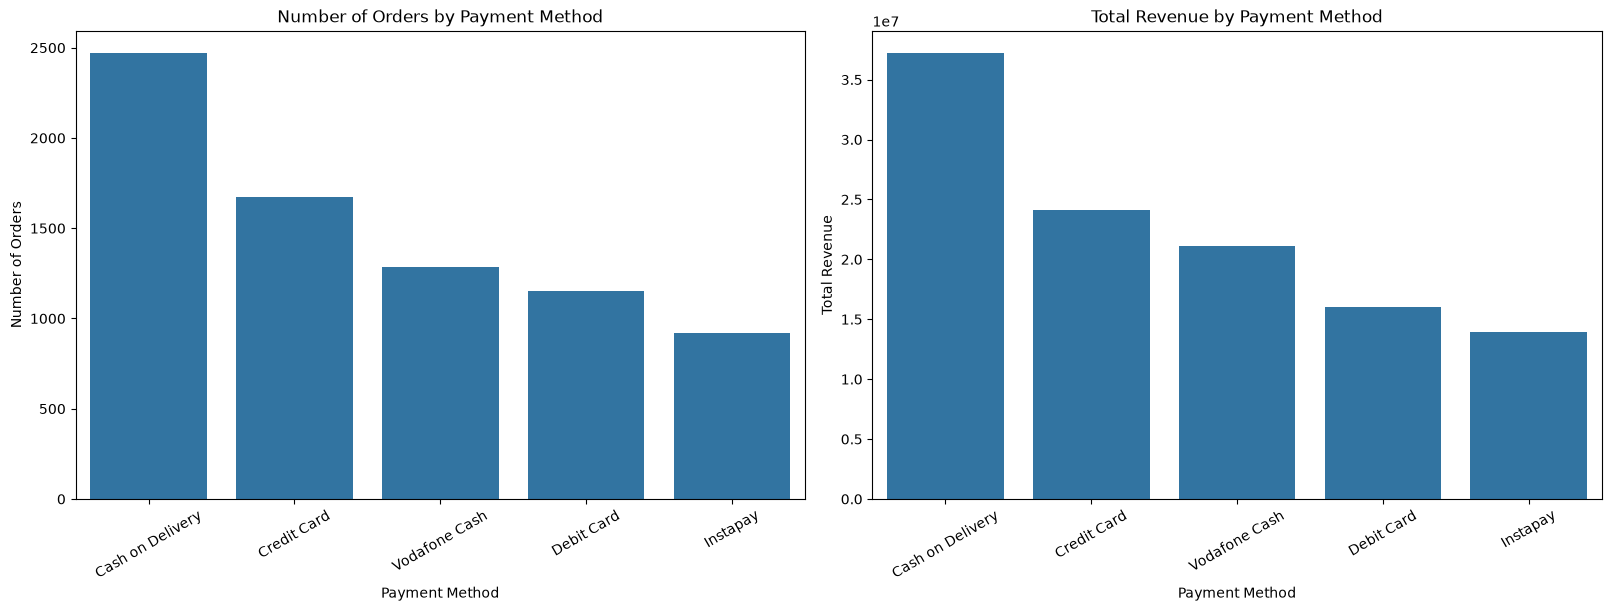

In [70]:
# Payment method: show both order count and total revenue.
payment_plot = payment_summary.reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
sns.barplot(data=payment_plot, x="Payment_Method", y="Orders", ax=axes[0])
axes[0].set_title("Number of Orders by Payment Method")
axes[0].set_xlabel("Payment Method")
axes[0].set_ylabel("Number of Orders")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(data=payment_plot, x="Payment_Method", y="Total_Revenue", ax=axes[1])
axes[1].set_title("Total Revenue by Payment Method")
axes[1].set_xlabel("Payment Method")
axes[1].set_ylabel("Total Revenue")
axes[1].tick_params(axis="x", rotation=30)

plt.show()

## Final Business Insights & Conclusion

After running the corrected analysis cells, write 5–10 evidence-based findings here. Each finding should include the actual value or percentage from the outputs above. Do not claim that discounts cause higher sales from a scatter plot alone; describe the observed association only. Also distinguish order count from units sold, and total revenue from average order value.

Suggested questions:
- Which category contributes the most to total revenue?
- Which city has the highest total revenue, and does it also have the most orders?
- Which products lead revenue generation?
- Which order status is most common by number of orders?
- Which payment method has the most orders versus the highest total revenue?
- How are discount rate and final revenue associated?

### Conclusion

Summarize the main business findings, mention important data limitations, and state one or two practical recommendations supported by the analysis.
